# Y3_mock_imweights: summary of every test

This notebook only **reads the outputs saved by the scripts** in this folder and plots them, so it runs in seconds. To refresh a number, rerun the script that produces it (named at the top of each section), then rerun this notebook.

| § | Question | Script → output | One-line answer |
|---|---|---|---|
| 1 | Is D = CSFD − SFD (what CSFD removes from SFD) correlated with CMB κ? | `dust_map_check.py` → `figures/dust_map_check.txt` | Yes: r(D, κ) ≈ −0.5 at ℓ < 100, falling to −0.1 at ℓ ~ 400. SFD and CSFD themselves are ~uncorrelated with κ. |
| 2 | Is D the CIB? (test against an independent CIB map) | `cib_check.py` → `figures/cib_check.txt` | Mostly: r(D, CIB) ≈ −0.4 to −0.57 at ℓ ≳ 90, for all 4 Lenz+19 maps. |
| 3 | Does the CIB alone explain r(D, κ)? (map-level Euclid test) | `cib_check.py` | No: measured r(D, κ) is 1.5–3× the CIB-route prediction, for every frequency and mask. Not CIB-map noise: the Lenz maps are ≥ 99% signal at 857 GHz on these scales. |
| 4 | Does D correlate with *our galaxies* beyond the CIB? (data Euclid test) | `euclid_data_check.py` → `figures/euclid_data_*.txt` | Yes for BGS/LRG: 2.4–6× the CIB route, decreasing with redshift; QSO consistent with the CIB route. Noise-free (odd × even) CIB auto, as in Euclid. |
| 5 | How much clustering does the linear regression remove on mocks (no systematics injected)? | `regress_*_mocks.py`, `compare_variants.py` → `figures/variants/*.npz` | Photo: ~20% at ℓ = 2–5, < 1% at ℓ ≳ 30. Spec: much milder. Dust variant choice ≲ 1%. |
| 6 | On the real data, does the dust-map choice change Cgκ? | `regress_*_data.py`, `compare_data_variants.py` → `figures/data_variants/*.npz` | Photo baseline is safe; fitting CSFD+SFD together removes 46–73% of Cgκ. Spec EBV_DIFF costs ~1% of Cgκ. |
| 7 | Open items | | BGS spec mocks rerun with the 3-map DESI default; ELG SysNet mocks. |

**Notation used throughout**
* **SFD**, **CSFD**: E(B−V) dust maps (Schlegel+98; Chiang 2023). CSFD = SFD with the large-scale-structure (CIB) contamination removed.
* **D = CSFD − SFD** = minus the LSS/CIB component that CSFD subtracts from SFD.
* **CIB**: Lenz, Doré & Lagache (2019) CIB maps (Planck HFI minus an HI-based dust model). They are built *without* galaxies, so they are an independent tracer of the CIB.
* **r_ℓ(A, B) = C_ℓ^{AB} / sqrt(C_ℓ^{AA} C_ℓ^{BB})**: the correlation coefficient per ℓ bin (nside-256 pseudo-C_ℓ, fsky-corrected, on the stated common footprint). It is dimensionless, lies in [−1, 1], and its noise per bin is ≈ 1/sqrt(N_modes); that is the grey band in the plots.

In [1]:
import glob, os, re
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = "/global/cfs/cdirs/desicollab/users/schiarenza/Y3_mock_imweights"
FIG = os.path.join(ROOT, "figures")
# categorical palette (validated, fixed order; dataviz default instance)
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "0.9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 2, "lines.markersize": 5, "legend.frameon": False, "legend.fontsize": 8,
    "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
})
RANGE = re.compile(r"\d+-\d+$")


def read_tables(path):
    # Parse the r_ell tables written by dust_map_check / cib_check / euclid_data_check.
    # Returns {(section, subsection): {"bins": (n,2) array, "meta": str, "rows": {label: values}}}.
    # Sections are the '==' lines, subsections the '--' lines (text before ':').
    # Rows labelled 'via CIB ...' are renamed '<previous measured label> via CIB'.
    out, sec, sub, meta, bins, last = {}, "", "", "", None, ""
    for line in open(path):
        st = line.strip()
        if st.startswith("=="):
            sec, sub, meta = st.strip("= ").split(":")[0].strip(), "", st
            continue
        if st.startswith("--"):
            sub, meta = st[2:].split(":")[0].strip(), st
            continue
        toks = st.split()
        if len(toks) >= 3 and all(RANGE.match(t) for t in toks[-3:]):
            bins = np.array([[int(x) for x in t.split("-")] for t in toks if RANGE.match(t)])
            continue
        vals = []
        for t in reversed(toks):
            try:
                vals.append(float(t))
            except ValueError:
                break
        if len(vals) < 5 or bins is None:
            continue
        label = " ".join(toks[: len(toks) - len(vals)])
        if label.startswith("via CIB") and last.endswith("measured"):
            label = last.replace(" measured", " via CIB")
        last = label
        d = out.setdefault((sec, sub), {"bins": bins, "meta": meta, "rows": {}})
        d["rows"][label] = np.array(vals[::-1])[: len(bins)]
    return out


def ell_centres(bins):
    return 0.5 * (bins[:, 0] + bins[:, 1])


def fsky_of(meta):
    m = re.search(r"fsky=([\d.]+)", meta)
    return float(m.group(1)) if m else None


def noise_band(ax, bins, fsky):
    # +-1/sqrt(N_modes) per bin: the scatter of r_ell for two uncorrelated maps.
    lc, dl = ell_centres(bins), bins[:, 1] - bins[:, 0]
    sig = 1 / np.sqrt((2 * lc + 1) * dl * fsky)
    ax.fill_between(lc, -sig, sig, color="0.88", lw=0, label=r"$\pm 1/\sqrt{N_{\rm modes}}$")


def finish(ax, ylabel=None, xlabel=r"multipole $\ell$", log=True):
    ax.axhline(0, color="0.4", lw=0.8)
    if log:
        ax.set_xscale("log")
    ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)

## 1. Map level: does D = CSFD − SFD correlate with CMB lensing κ?
*Script:* `dust_map_check.py` → `figures/dust_map_check.txt`. *Footprint:* the photo footprint ∩ each lensing mask.

**What is plotted:** r_ℓ(X, κ) for X = D, SFD, CSFD and LSS. LSS is the CSFD release's own "LSS/CIB" intensity map, with SFD − CSFD ∝ LSS, so it mirrors D. One panel for Planck PR4 κ, one for ACT DR6 κ.

**How to read it:** a dust map should not correlate with CMB lensing. Any r significantly outside the grey band means the map contains extragalactic structure that traces the same matter as κ.

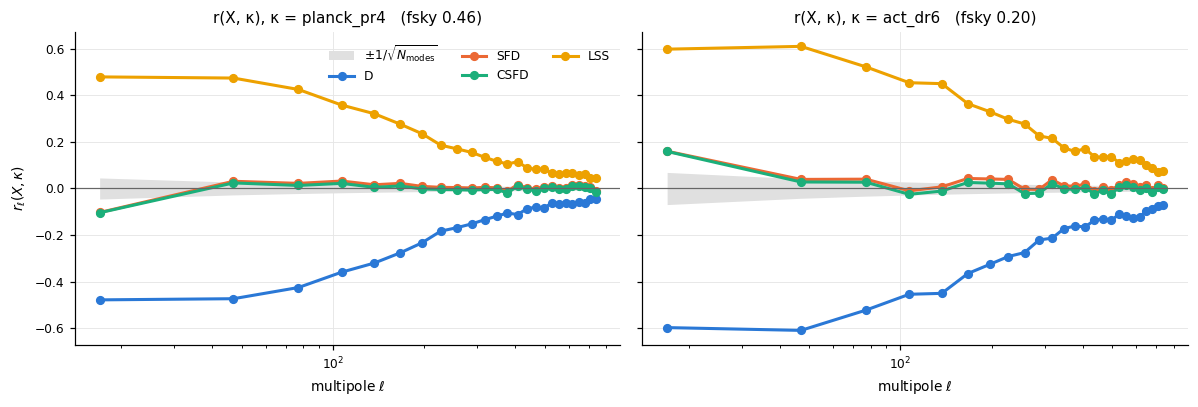

In [2]:
t = read_tables(os.path.join(FIG, "dust_map_check.txt"))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, lens in zip(axes, ("planck_pr4", "act_dr6")):
    key = next(k for k in t if k[1] == lens)
    d = t[key]
    noise_band(ax, d["bins"], fsky_of(d["meta"]))
    for i, x in enumerate(("D", "SFD", "CSFD", "LSS")):
        ax.plot(ell_centres(d["bins"]), d["rows"][f"r({x},k)"], marker="o", color=PAL[i], label=x)
    ax.set_title(f"r(X, κ), κ = {lens}   (fsky {fsky_of(d['meta']):.2f})")
    finish(ax, r"$r_\ell(X,\kappa)$" if lens == "planck_pr4" else None)
axes[0].legend(ncol=3)
plt.tight_layout(); plt.show()

**Result.** r(D, κ) ≈ −0.5 at ℓ < 100 (Planck), ≈ −0.6 (ACT), falling to ≈ −0.1 at ℓ ~ 400. SFD and CSFD themselves are consistent with ≈ 0, because D is only ~2% of the SFD rms. So fitting SFD *or* CSFD alone is harmless, but a fit that can form the *difference* CSFD − SFD can reach a κ-correlated direction.

## 2. Is D the CIB? Check against the independent Lenz+19 CIB
*Script:* `cib_check.py` → `figures/cib_check.txt`. *Footprint:* CIB mask ∩ photo footprint ∩ CSFD cosmology mask (fsky ≈ 0.15).
*CIB maps:* 353, 545 and 857 GHz on the N_HI < 2.5×10²⁰ cm⁻² mask (20% Galactic-plane mask), plus 857 GHz on the looser N_HI < 4×10²⁰ mask (40% Galactic-plane mask).

The CSFD "LSS" correction is reconstructed **from galaxy cross-correlations**, so its correlation with galaxies or κ is partly built in. The Lenz CIB is built from Planck HFI minus an HI-based dust model, with **no galaxies**. If D correlates with the Lenz CIB, then D really contains the CIB.

**What is plotted:**
* left: r_ℓ(D, CIB) for each of the 4 CIB maps;
* right: r_ℓ(X, CIB) for X = SFD, CSFD and HI at 857 GHz. HI is a control: the Lenz maps are HI-cleaned, so it should be ≈ 0.

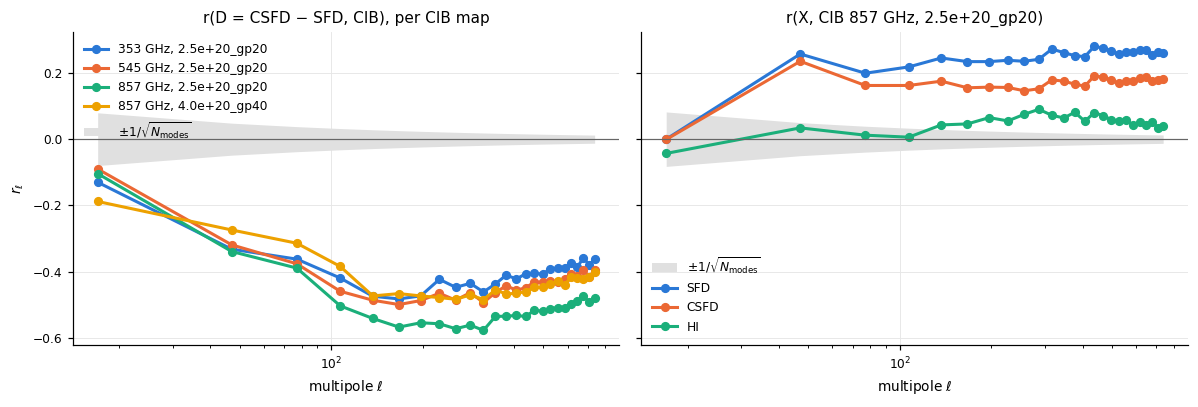

**Mean over ℓ ≥ 92**

| CIB map | r(D,CIB) | r(SFD,CIB) | r(CSFD,CIB) | r(HI,CIB) |
|---|---|---|---|---|
| 353 GHz, 2.5e+20_gp20 | -0.41 | +0.21 | +0.14 | +0.06 |
| 545 GHz, 2.5e+20_gp20 | -0.45 | +0.22 | +0.15 | +0.06 |
| 857 GHz, 2.5e+20_gp20 | -0.53 | +0.25 | +0.17 | +0.06 |
| 857 GHz, 4.0e+20_gp40 | -0.45 | +0.21 | +0.17 | +0.05 |

In [3]:
cib = read_tables(os.path.join(FIG, "cib_check.txt"))
maps = [k[0] for k in cib if k[1] == "CIB & photo & CSFD-cosmo"]
FOOT = "CIB & photo & CSFD-cosmo"
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for i, m in enumerate(maps):
    d = cib[(m, FOOT)]
    axes[0].plot(ell_centres(d["bins"]), d["rows"]["r(D, CIB)"], marker="o", color=PAL[i], label=m)
d = cib[(maps[0], FOOT)]
noise_band(axes[0], d["bins"], fsky_of(d["meta"]))
axes[0].set_title("r(D = CSFD − SFD, CIB), per CIB map")
m857 = next(m for m in maps if m.startswith("857") and "2.5e" in m)
d = cib[(m857, FOOT)]
noise_band(axes[1], d["bins"], fsky_of(d["meta"]))
for i, x in enumerate(("SFD", "CSFD", "HI")):
    axes[1].plot(ell_centres(d["bins"]), d["rows"][f"r({x}, CIB)"], marker="o", color=PAL[i], label=x)
axes[1].set_title(f"r(X, CIB {m857})")
finish(axes[0], r"$r_\ell$"); finish(axes[1])
axes[0].legend(); axes[1].legend()
plt.tight_layout(); plt.show()

rows = []
for m in maps:
    d = cib[(m, FOOT)]
    hi = d["bins"][:, 0] >= 92
    rows.append(f"| {m} | {d['rows']['r(D, CIB)'][hi].mean():+.2f} | {d['rows']['r(SFD, CIB)'][hi].mean():+.2f} | "
                f"{d['rows']['r(CSFD, CIB)'][hi].mean():+.2f} | {d['rows']['r(HI, CIB)'][hi].mean():+.2f} |")
display(Markdown("**Mean over ℓ ≥ 92**\n\n| CIB map | r(D,CIB) | r(SFD,CIB) | r(CSFD,CIB) | r(HI,CIB) |\n|---|---|---|---|---|\n" + "\n".join(rows)))

**Result.** r(D, CIB) ≈ −0.4 to −0.57 at ℓ ≳ 90 for every map, strongest at 857 GHz, where the CIB is brightest relative to the noise. D is therefore CIB-dominated. CSFD keeps a smaller CIB correlation than SFD (it removes about a third of it). The HI control is ≈ 0, as it should be.

## 3. Map-level Euclid test: does the CIB explain r(D, κ)?
*Script:* `cib_check.py`. *Footprint:* the §2 footprint ∩ each lensing mask.

**The logic.** If the **only** thing D and κ have in common is the CIB, then the correlation has to "go through" the CIB, and it factorises:

$$ r(D,\kappa)\;=\;r(D,\mathrm{CIB})\;\times\;r(\mathrm{CIB},\kappa) \qquad\text{(CIB route)}.$$

This is the test used in the Euclid dust/CIB analysis. A measured |r(D, κ)| **larger** than the product means D contains another κ-correlated component that is not in the Lenz CIB.

**What is plotted** (one panel per lensing map):
* **points**: the measured r(D, κ);
* **lines**: the CIB-route prediction for each CIB map;
* **dashed**: r(CIB, κ) for the 857 GHz map, for reference.

The bottom row shows measured / predicted. A value of 1 means fully explained by the CIB.

**Same test as Euclid.** This is the test in C. Daley's CMBX KP2-3 talk (22 Oct 2026, slide 13, "Extinction crosses follow the CIB, closest at 857 GHz"; https://cailmdaley.github.io/talks/2610_KP23_Napoli/). There, the template E (Planck E(B−V)) = dust + α·CIB, the dust is uncorrelated with the tracers, so r(t, E) = r(t, CIB)·r(CIB, E) band by band, and nothing is fitted. Here our D plays the role of their E.

**The CIB auto-spectrum is noise-free, as in Euclid.** C^{CIB,CIB} is the cross-spectrum of the odd-ring and even-ring half maps. Those halves see the same sky with independent noise, so their cross has no noise bias. The full-mission auto has the CIB map's noise in it: it lowers both r(·, CIB) factors and biases the prediction towards 0 by S/(S+N). That older prediction is drawn **dotted** for comparison. The second figure shows S/(S+N) per ℓ, i.e. how much the full-mission auto overestimates the CIB power.

A second difference: Euclid's template is a dust-emission map with a CIB leak. Our D = CSFD − SFD is the LSS component that CSFD **reconstructed from galaxy cross-correlations** (Chiang 2023). So we expect D to correlate with κ and galaxies beyond the CIB route even with a noise-free CIB.

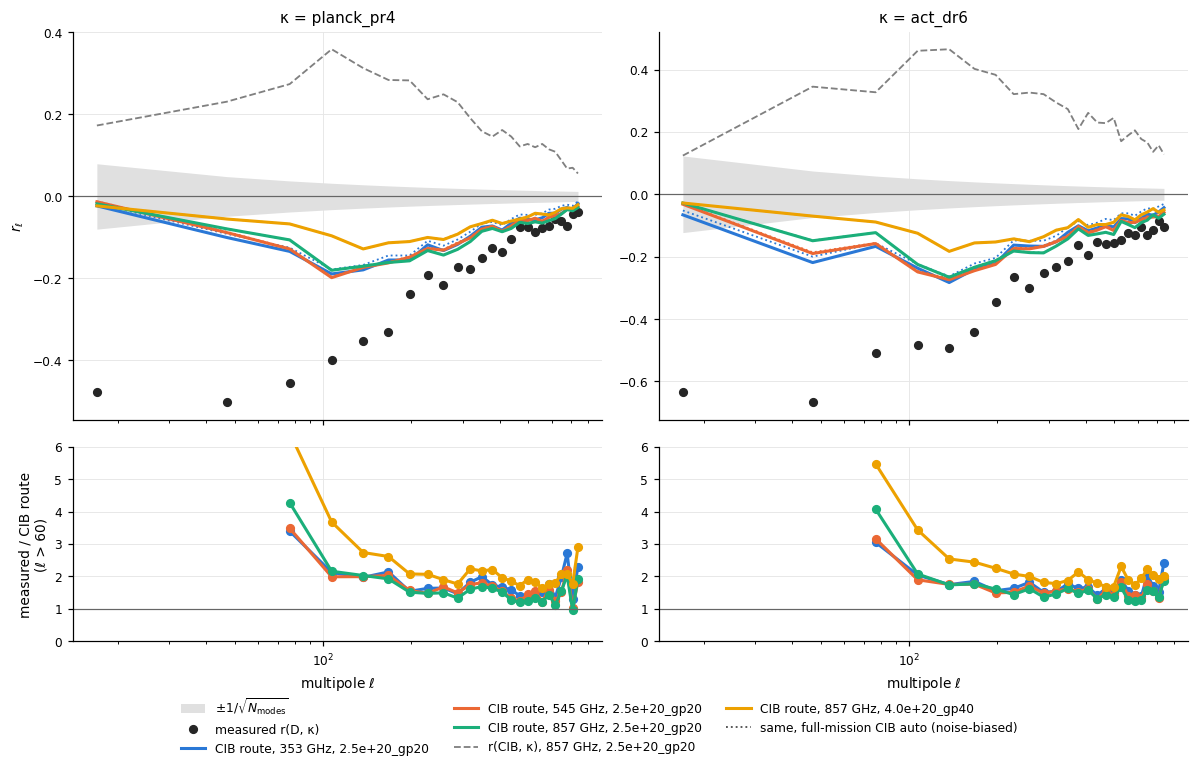

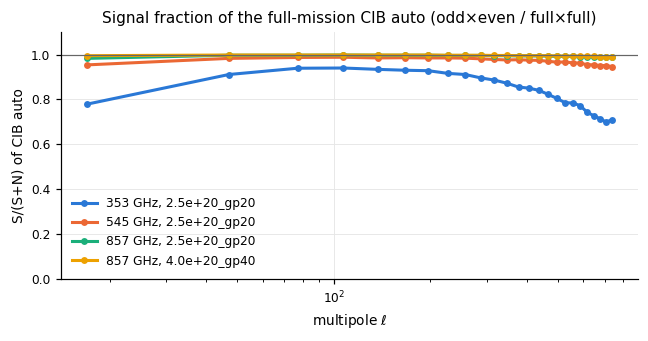

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for col, lens in enumerate(("planck_pr4", "act_dr6")):
    ax, axr = axes[0, col], axes[1, col]
    for i, m in enumerate(maps):
        d = cib[(m, f"{lens} x CIB {m}")]
        lc = ell_centres(d["bins"])
        meas, pred = d["rows"]["r(D, kappa) measured"], d["rows"]["r(D,CIB) r(CIB,kappa)"]
        if i == 0:
            noise_band(ax, d["bins"], fsky_of(d["meta"]))
            ax.plot(lc, meas, "o", color="0.15", label="measured r(D, κ)")
        ax.plot(lc, pred, color=PAL[i], label=f"CIB route, {m}")
        if "r(D,CIB) r(CIB,kappa) fullmission" in d["rows"]:
            ax.plot(lc, d["rows"]["r(D,CIB) r(CIB,kappa) fullmission"], ":", lw=1.2, color=PAL[i])
        axr.plot(lc[lc > 60], (meas / pred)[lc > 60], marker="o", color=PAL[i])
        if m == m857:
            ax.plot(lc, d["rows"]["r(CIB, kappa)"], "--", lw=1.2, color="0.5", label=f"r(CIB, κ), {m}")
    ax.set_title(f"κ = {lens}")
    finish(ax, r"$r_\ell$" if col == 0 else None, xlabel="")
    axr.axhline(1, color="0.4", lw=0.8); axr.set_xscale("log"); axr.set_xlabel(r"multipole $\ell$")
    axr.set_ylim(0, 6)
    if col == 0:
        axr.set_ylabel("measured / CIB route\n(ℓ > 60)")
h, l = axes[0, 0].get_legend_handles_labels()
h.append(plt.Line2D([], [], ls=":", lw=1.2, color="0.3")); l.append("same, full-mission CIB auto (noise-biased)")
fig.legend(h, l, loc="lower center", ncol=3, fontsize=8, bbox_to_anchor=(0.5, -0.08))
plt.tight_layout(); plt.show()

# how much of the full-mission CIB auto is signal: S/(S+N) = C^{odd x even} / C^{full x full}
fig, ax = plt.subplots(figsize=(6, 3.2))
for i, m in enumerate(maps):
    d = cib[(m, f"planck_pr4 x CIB {m}")]
    if "CIB auto S/(S+N)" in d["rows"]:
        ax.plot(ell_centres(d["bins"]), d["rows"]["CIB auto S/(S+N)"], marker="o", ms=3.5, color=PAL[i], label=m)
ax.axhline(1, color="0.4", lw=0.8); ax.set_ylim(0, 1.1); ax.set_xscale("log")
ax.set_xlabel(r"multipole $\ell$"); ax.set_ylabel("S/(S+N) of CIB auto")
ax.set_title("Signal fraction of the full-mission CIB auto (odd×even / full×full)")
ax.legend(); plt.tight_layout(); plt.show()

**Noise check (odd × even).** The full-mission CIB auto is S/(S+N) ≈ 0.99 signal at 857 GHz, ≈ 0.98 at 545 GHz and 0.85–0.94 at 353 GHz, over ℓ = 32–767. So the noise-free prediction moves by < 1% at 857 GHz and by 5–15% at 353 GHz (solid vs dotted). On these scales, CIB-map noise does **not** explain the gap.

**Result.** The measured r(D, κ) is the same whichever CIB map is used, ≈ −0.15 to −0.3 at ℓ ≥ 92. The CIB-route prediction is 1.5–3× smaller in magnitude for **every** frequency and mask, and the gap is much larger at ℓ < 60. Changing frequency or mask does not close the gap, so the excess is not a quirk of one CIB map. It points to D containing κ-correlated structure beyond the CIB. That fits the fact that the CSFD LSS correction was reconstructed from galaxies.

## 4. Data Euclid test: dust and CIB versus **our** galaxy samples
*Script:* `euclid_data_check.py` → `figures/euclid_data_<sample>_<T>.{txt,png}`. It reads the real-data sidecars from `regress_*_data.py`.

**What the saved figures `figures/euclid_data_<sample>_<T>.png` show:**
* **Rows:** the 4 Lenz CIB maps.
* **Columns:** two versions of the galaxy overdensity δ_g, both built at nside 256 from the real catalog over its randoms:
  * **g_raw**: weighted only by the analysis weight *without* the imaging weight (photo: Z_WEIGHT; spec: WEIGHT·WEIGHT_FKP/WEIGHT_SYS). This is the sample's actual correlation with the dust maps.
  * **g_imlin**: the same × our baseline WEIGHT_IMLIN. This is what remains after the linear regression.
* **Points:** the measured r_ℓ(δ_g, X), for X = SFD (blue), D = CSFD − SFD (orange) and EBV_DIFF_GR (green).
* **Lines (same colour):** the CIB-route prediction r(δ_g, CIB) × r(CIB, X), with the noise-free odd × even CIB auto, i.e. what the correlation would be if galaxies and X shared *only* the CIB. **Dotted:** the same prediction with the noise-biased full-mission auto (the version before 2026-10-26), for comparison.
* **Grey band:** ±1/sqrt(N_modes).
* **Footprint:** data mask (randoms ≥ 20% of the median) ∩ CIB mask. EBV_DIFF rows are further restricted to where EBV_DIFF is defined, i.e. where there are DESI stars.

**How to read it:** points on their line mean the galaxy–X correlation is fully explained by the CIB. Points beyond the line mean X carries another galaxy-correlated component.

This is the data-side analogue of the Euclid test (Daley, slide 13), with our δ_g in place of their tracer t and X in place of their extinction template, including the noise-free odd × even CIB auto.

Below, the same quantities for every tracer at **857 GHz, N_HI < 2.5e20**, on g_raw.

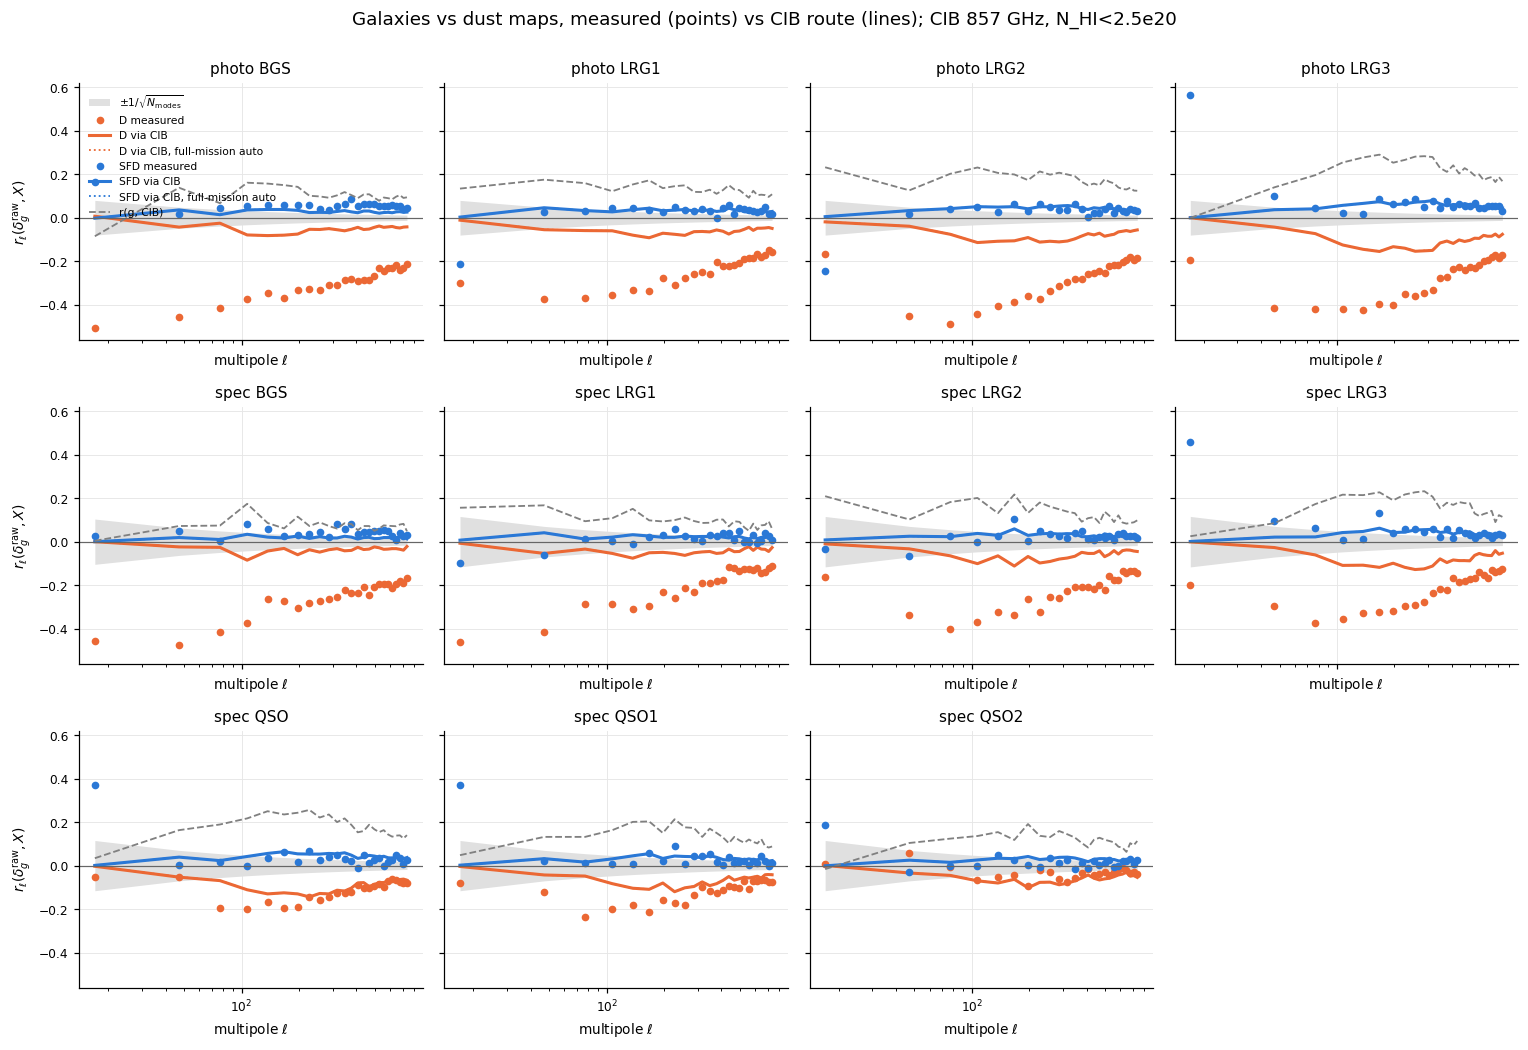

**Mean over ℓ ≥ 92 (g_raw, 857 GHz 2.5e20)**

| sample | r(g,CIB) | r(g,D) measured | r(g,D) via CIB | ratio | r(g,SFD) | r(g,CSFD) |
|---|---|---|---|---|---|---|
| photo BGS | +0.107 | -0.283 | -0.053 | 5.3 | +0.056 | +0.006 |
| photo LRG1 | +0.124 | -0.232 | -0.062 | 3.8 | +0.034 | -0.006 |
| photo LRG2 | +0.169 | -0.277 | -0.085 | 3.3 | +0.038 | -0.010 |
| photo LRG3 | +0.226 | -0.275 | -0.113 | 2.4 | +0.055 | +0.008 |
| spec BGS | +0.077 | -0.235 | -0.038 | 6.2 | +0.044 | +0.006 |
| spec LRG1 | +0.088 | -0.180 | -0.045 | 4.0 | +0.020 | -0.007 |
| spec LRG2 | +0.125 | -0.219 | -0.063 | 3.5 | +0.028 | -0.006 |
| spec LRG3 | +0.170 | -0.215 | -0.086 | 2.5 | +0.040 | +0.007 |
| spec QSO | +0.185 | -0.117 | -0.096 | 1.2 | +0.028 | +0.010 |
| spec QSO1 | +0.138 | -0.118 | -0.072 | 1.6 | +0.025 | +0.007 |
| spec QSO2 | +0.119 | -0.040 | -0.062 | 0.6 | +0.013 | +0.007 |

In [5]:
TR = [("photo", t) for t in ("BGS", "LRG1", "LRG2", "LRG3")] + [("spec", t) for t in ("BGS", "LRG1", "LRG2", "LRG3", "QSO", "QSO1", "QSO2")]
CIBKEY = "CIB 857 GHz, 2.5e+20_gp20"
fig, axes = plt.subplots(3, 4, figsize=(14, 9.5), sharex=True, sharey=True)
summary = []
for ax, (s, T) in zip(axes.flat, TR):
    path = os.path.join(FIG, f"euclid_data_{s}_{T}.txt")
    if not os.path.exists(path):
        ax.set_title(f"{s} {T}: missing"); continue
    e = read_tables(path)[(CIBKEY, "")]
    lc, rows = ell_centres(e["bins"]), e["rows"]
    noise_band(ax, e["bins"], fsky_of(e["meta"]))
    for i, x in enumerate(("D", "SFD")):
        c = PAL[1] if x == "D" else PAL[0]
        ax.plot(lc, rows[f"r(g_raw, {x}) measured"], "o", ms=4, color=c, label=f"{x} measured")
        ax.plot(lc, rows[f"r(g_raw, {x}) via CIB"], color=c, label=f"{x} via CIB")
        if f"r(g_raw, {x}) via CIB fullmission" in rows:
            ax.plot(lc, rows[f"r(g_raw, {x}) via CIB fullmission"], ":", lw=1.2, color=c, label=f"{x} via CIB, full-mission auto")
    ax.plot(lc, rows["r(g_raw, CIB)"], "--", lw=1.2, color="0.5", label="r(g, CIB)")
    ax.set_title(f"{s} {T}")
    finish(ax)
    hi = e["bins"][:, 0] >= 92
    m, p = rows["r(g_raw, D) measured"][hi].mean(), rows["r(g_raw, D) via CIB"][hi].mean()
    summary.append(f"| {s} {T} | {rows['r(g_raw, CIB)'][hi].mean():+.3f} | {m:+.3f} | {p:+.3f} | {m / p:.1f} | "
                   f"{rows['r(g_raw, SFD) measured'][hi].mean():+.3f} | {rows['r(g_raw, CSFD) measured'][hi].mean():+.3f} |")
axes.flat[-1].axis("off")
axes[0, 0].legend(fontsize=7)
for ax in axes[:, 0]:
    ax.set_ylabel(r"$r_\ell(\delta_g^{\rm raw}, X)$")
plt.suptitle("Galaxies vs dust maps, measured (points) vs CIB route (lines); CIB 857 GHz, N_HI<2.5e20", y=1.0)
plt.tight_layout(); plt.show()
display(Markdown("**Mean over ℓ ≥ 92 (g_raw, 857 GHz 2.5e20)**\n\n| sample | r(g,CIB) | r(g,D) measured | r(g,D) via CIB | ratio | r(g,SFD) | r(g,CSFD) |\n|---|---|---|---|---|---|---|\n" + "\n".join(summary)))

**Result.**
* **BGS and LRG (photo and spec):** mean r(δ_g, D) over ℓ ≥ 92 ≈ −0.18 to −0.28, which is 2.4–6× the CIB-route prediction. The excess falls with redshift: BGS 5–6×, LRG1 ~4×, LRG2 ~3.5×, LRG3 ~2.5×. D, i.e. the CSFD LSS correction, carries galaxy-correlated structure beyond the CIB, mostly at low z. That fits a correction reconstructed from galaxy cross-correlations dominated by low-z galaxies.
* **QSO:** consistent with the CIB route (ratio 0.6–1.7). The CIB correlates with the high-z samples as strongly as D does (r(g, CIB) ≈ 0.12–0.18).
* These use the noise-free odd × even CIB auto. Swapping it for the full-mission auto (dotted lines) changes nothing visible at 857 GHz, because the map is ≥ 99% signal on these scales (§3). The excess is not CIB-map noise.
* **r(δ_g, SFD)** ≈ +0.03 to +0.06, matching its CIB-route prediction: SFD's small galaxy correlation is its CIB contamination. **r(δ_g, CSFD) ≈ 0**: CSFD itself is clean.
* In the saved figures, the **g_imlin** column looks like g_raw for D, because the baseline regression fits CSFD (or SFD), not D. The D-direction is left alone, which is the safe outcome. It only gets removed if a fit can form CSFD − SFD (§6).

## 5. Mocks: how much clustering does the regression remove? (mode removal)
*Scripts:* `regress_photo_mocks.py`, `regress_spec_mocks.py`, `compare_variants.py` → `figures/variants/<sample>_<lensmap>_<T>.npz`.
The lognormal mocks have **no injected systematics**, so any power the weights remove is real clustering lost to the fit. That is the correction needed for the data.

**What is plotted:** ⟨C_ℓ^gg(baseline weights)⟩ / ⟨C_ℓ^gg(unweighted)⟩ over the mocks (shot-noise subtracted pseudo-C_ℓ), with the error on the mean. Left: photo samples. Right: spec samples (act_dr6 mocks).

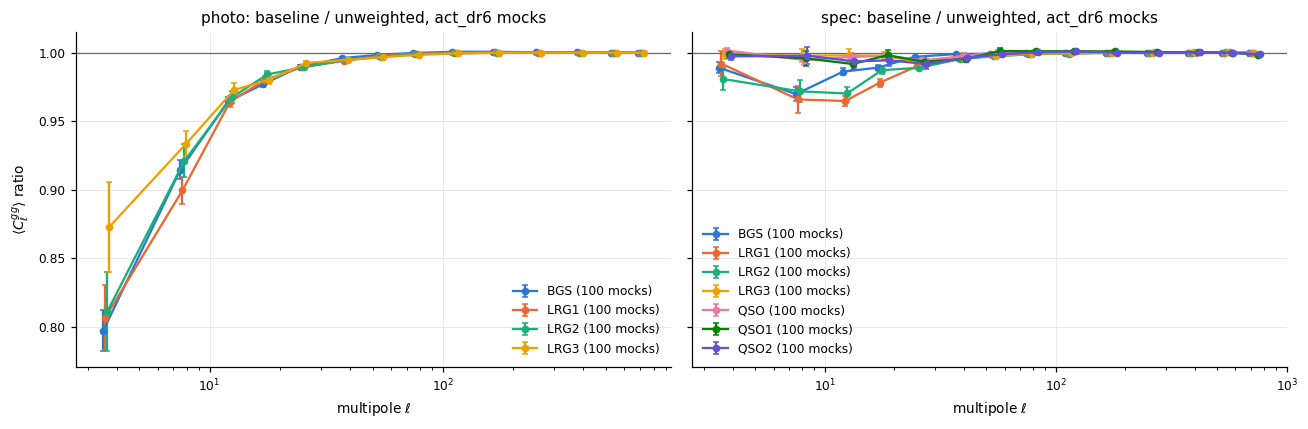

In [6]:
def mock_ratio(path, num, den):
    z = np.load(path)
    r = z[f"cl_{num}"] / z[f"cl_{den}"]
    return z["ell_edges"], r.mean(0), r.std(0, ddof=1) / np.sqrt(len(r)), len(r)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, s, trs in ((axes[0], "photo", ("BGS", "LRG1", "LRG2", "LRG3")),
                   (axes[1], "spec", ("BGS", "LRG1", "LRG2", "LRG3", "QSO", "QSO1", "QSO2"))):
    for i, T in enumerate(trs):
        p = os.path.join(FIG, "variants", f"{s}_act_dr6_{T}.npz")
        if not os.path.exists(p):
            continue
        E, m, e, n = mock_ratio(p, "WEIGHT_IMLIN", "UNWEIGHTED")
        lc = 0.5 * (E[:-1] + E[1:] - 1)
        ax.errorbar(lc * (1 + 0.02 * i), m, e, marker="o", ms=4, lw=1.5, capsize=2, color=PAL[i], label=f"{T} ({n} mocks)")
    ax.axhline(1, color="0.4", lw=0.8); ax.set_xscale("log"); ax.set_xlabel(r"multipole $\ell$")
    ax.set_title(f"{s}: baseline / unweighted, act_dr6 mocks"); ax.legend()
axes[0].set_ylabel(r"$\langle C_\ell^{gg}\rangle$ ratio")
plt.tight_layout(); plt.show()

**Result.**
* **Photo:** 0.79–0.87 at ℓ = 2–5, 0.90–0.93 at ℓ = 6–9, ~0.97 at ℓ = 10–14, and < 1% at ℓ ≳ 30.
* **Spec:** much milder; LRG 0.97–1.00 at ℓ < 20, QSO within ~1%. This is the mode-removal correction to apply to the data Cℓ. Gerrit measures it on the analysis grid from the sidecars in `outputs/`.
* **Spec BGS** uses the DESI 3-map default (STARDENS, GALDEPTH_R, HI; rerun 2026-10-26): 0.989 (ℓ = 2–5), 0.970 (6–9), ≤ 0.3% at ℓ ≥ 20. The old 5-map list removed 0.5–1.4% more at ℓ < 20.

**Dust-variant choice on mocks** (variant / baseline, ℓ ≥ 10): ≤ 0.05% for SFD↔CSFD and ≲ 1.5% for spec CSFD+HI or no-HI. See `README.md` → Full 100-mock results.

## 6. Real data: does the dust-map choice change Cgκ?
*Scripts:* `regress_photo_data.py`, `regress_spec_data.py` (real catalogs, same fit as the mocks), `compare_data_variants.py` → `figures/data_variants/<sample>_<T>.npz`.

**What is plotted:** for each variant, (C_ℓ^gκ(variant) − C_ℓ^gκ(baseline)) / σ_Knox(C_ℓ^gκ), for ACT DR6 and Planck PR4. Each variant changes only the imaging weight; all else is fixed (footprint, mask, analysis weights). σ_Knox is the per-bin Gaussian error on C^gκ, so |shift/σ| ≪ 1 means the choice is irrelevant at the per-bin level.

The variants (`config.yaml`):
* **photo** (baseline CSFD+HI):
  * `SFDHI` = SFD+HI
  * `CSFDONLY` = CSFD alone
  * `SPECLIKE` = the spec-BGS-like 4-map list
  * `CSFDSFDHI` = CSFD+SFD+HI, a data-only diagnostic that spans D
* **spec** (baseline = DESI default):
  * `CSFD` = EBV_DIFF re-referenced to CSFD
  * `CSFDHI` = CSFD+HI in place of EBV_DIFF
  * `NOHI` = no HI
  * `ALLEBV` = BGS + EBV_DIFF, the old 5-map list
  * `DESI` = the official catalog weight, a check: it should sit at 0

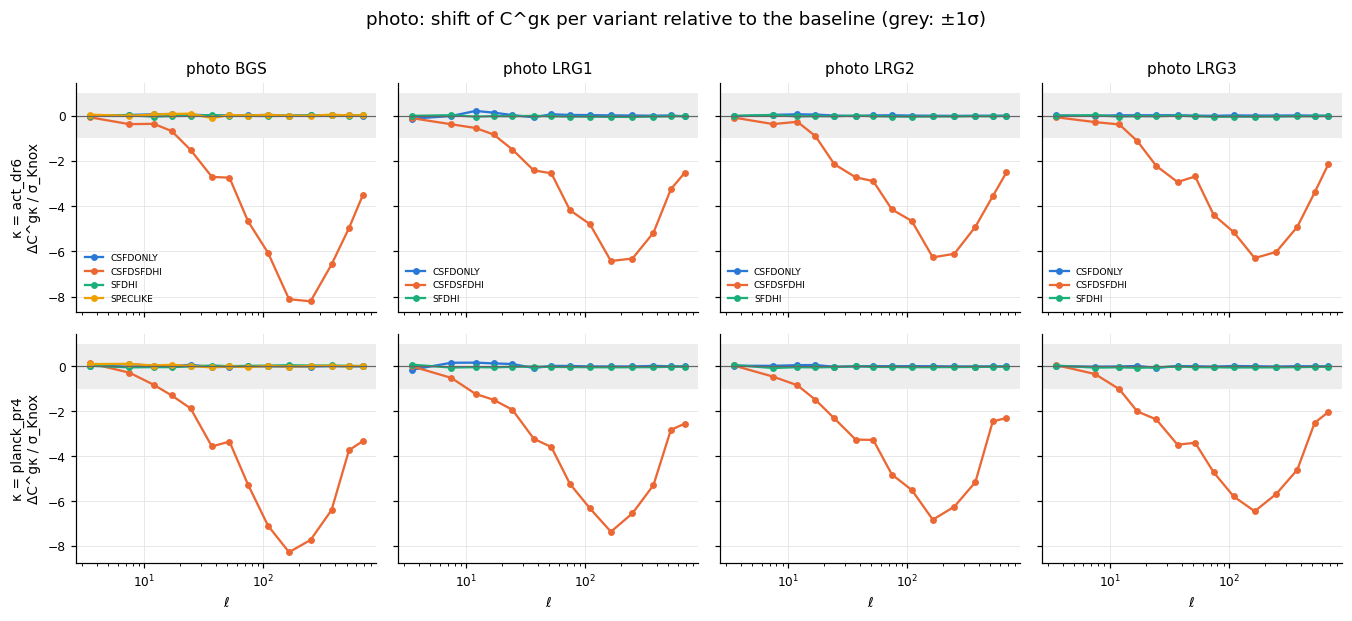

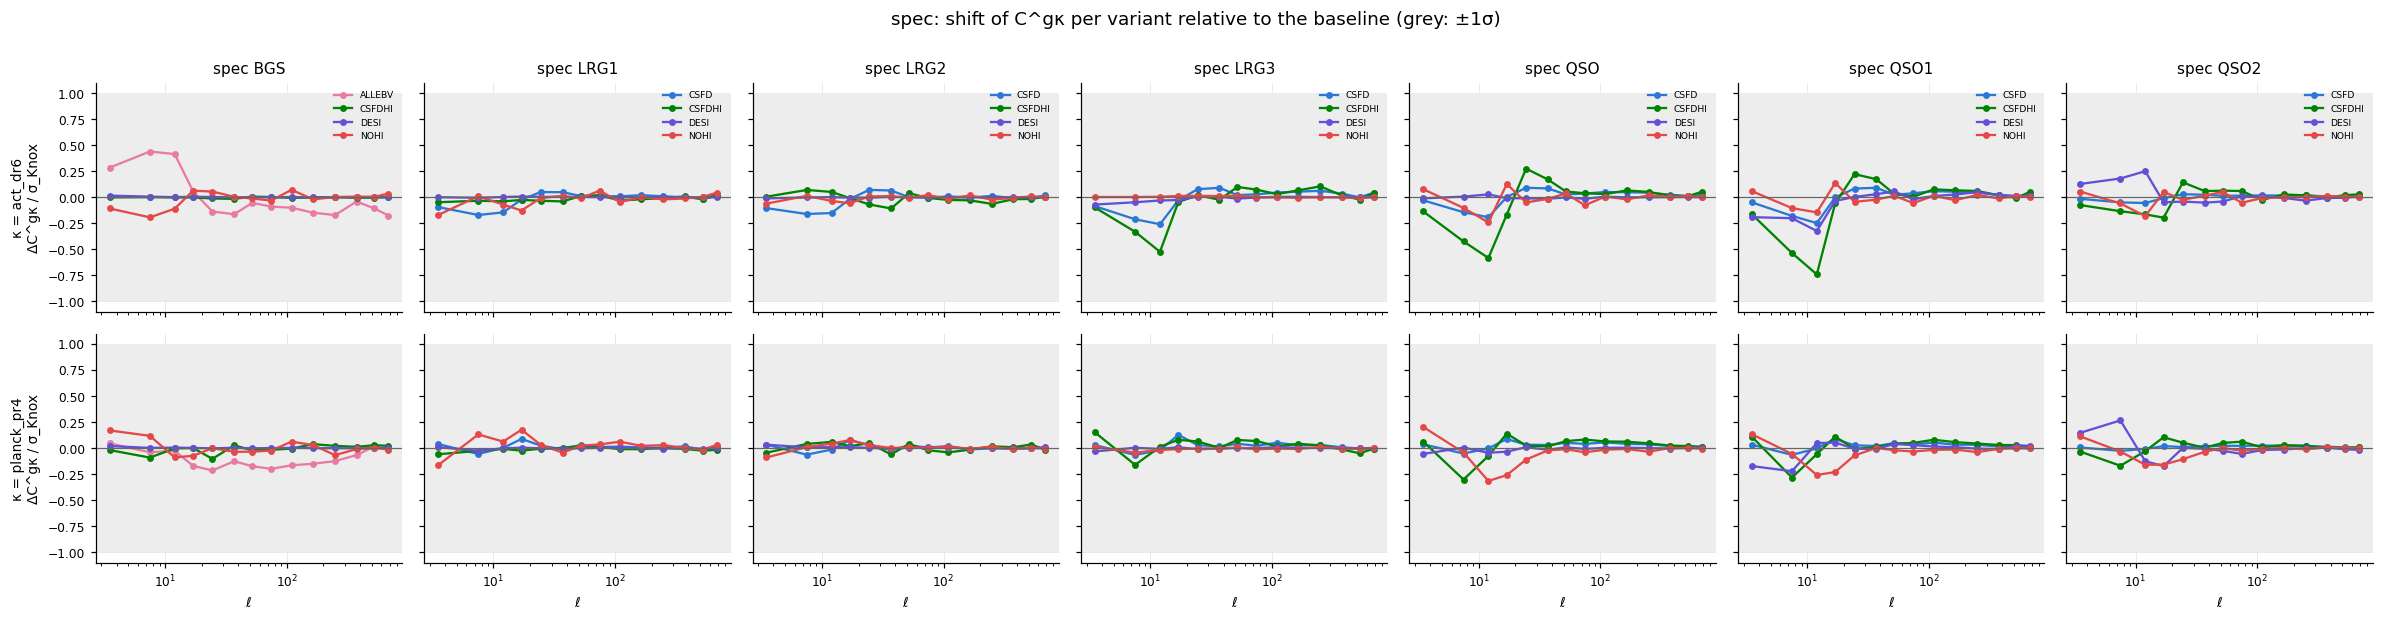

In [7]:
def data_npz(s, T):
    p = os.path.join(FIG, "data_variants", f"{s}_{T}.npz")
    return np.load(p) if os.path.exists(p) else None

def variants_of(z):
    return [k[len("cgg_"):] for k in z if k.startswith("cgg_") and k not in ("cgg_UNWEIGHTED", "cgg_WEIGHT_IMLIN")]

VCOL = {}
for s, trs in (("photo", ("BGS", "LRG1", "LRG2", "LRG3")), ("spec", ("BGS", "LRG1", "LRG2", "LRG3", "QSO", "QSO1", "QSO2"))):
    fig, axes = plt.subplots(2, len(trs), figsize=(3.1 * len(trs), 5.6), sharex=True, sharey="row")
    for j, T in enumerate(trs):
        z = data_npz(s, T)
        if z is None:
            continue
        E = z["ell_edges"]; lc = 0.5 * (E[:-1] + E[1:] - 1)
        for r, L in enumerate(("act_dr6", "planck_pr4")):
            ax = axes[r, j]
            ax.axhspan(-1, 1, color="0.93", lw=0)
            for v in variants_of(z):
                VCOL.setdefault(v, PAL[len(VCOL) % len(PAL)])
                d = (z[f"cgk_{L}_{v}"] - z[f"cgk_{L}_WEIGHT_IMLIN"]) / z[f"sigma_{L}"]
                ax.plot(lc, d, marker="o", ms=3.5, lw=1.5, color=VCOL[v], label=v.replace("WEIGHT_IMLIN_", ""))
            ax.axhline(0, color="0.4", lw=0.8); ax.set_xscale("log")
            if r == 0: ax.set_title(f"{s} {T}")
            if j == 0: ax.set_ylabel(f"κ = {L}\nΔC^gκ / σ_Knox")
            if r == 1: ax.set_xlabel(r"$\ell$")
        axes[0, j].legend(fontsize=6)
    plt.suptitle(f"{s}: shift of C^gκ per variant relative to the baseline (grey: ±1σ)", y=1.0)
    plt.tight_layout(); plt.show()

In [8]:
rows = []
for s, trs in (("photo", ("BGS", "LRG1", "LRG2", "LRG3")), ("spec", ("BGS", "LRG1", "LRG2", "LRG3", "QSO", "QSO1", "QSO2"))):
    for T in trs:
        z = data_npz(s, T)
        if z is None:
            continue
        E = z["ell_edges"]; hi = E[:-1] >= 30
        for v in variants_of(z):
            cells = []
            for L in ("act_dr6", "planck_pr4"):
                ratio = z[f"cgk_{L}_{v}"][hi].sum() / z[f"cgk_{L}_WEIGHT_IMLIN"][hi].sum()
                mx = np.abs((z[f"cgk_{L}_{v}"] - z[f"cgk_{L}_WEIGHT_IMLIN"]) / z[f"sigma_{L}"])[hi].max()
                cells.append(f"{ratio:.3f} | {mx:.2f}")
            gg = z[f"cgg_{v}"][E[:-1] >= 10] / z["cgg_WEIGHT_IMLIN"][E[:-1] >= 10]
            rows.append(f"| {s} {T} | {v.replace('WEIGHT_IMLIN_', '')} | " + " | ".join(cells) + f" | {np.abs(gg - 1).max():.3f} |")
display(Markdown("**Summary, ℓ ≥ 30** (ratio = Σ C^gκ(variant) / Σ C^gκ(baseline); max |Δ/σ| per bin; Cgg: max |ratio − 1| at ℓ ≥ 10)\n\n"
                 "| sample | variant | ACT ratio | ACT max\\|Δ/σ\\| | Planck ratio | Planck max\\|Δ/σ\\| | Cgg max\\|Δ\\| |\n|---|---|---|---|---|---|---|\n" + "\n".join(rows)))

**Summary, ℓ ≥ 30** (ratio = Σ C^gκ(variant) / Σ C^gκ(baseline); max |Δ/σ| per bin; Cgg: max |ratio − 1| at ℓ ≥ 10)

| sample | variant | ACT ratio | ACT max\|Δ/σ\| | Planck ratio | Planck max\|Δ/σ\| | Cgg max\|Δ\| |
|---|---|---|---|---|---|---|
| photo BGS | CSFDONLY | 1.002 | 0.04 | 0.997 | 0.03 | 0.013 |
| photo BGS | CSFDSFDHI | 0.299 | 8.21 | 0.268 | 8.28 | 0.192 |
| photo BGS | SFDHI | 1.002 | 0.02 | 1.005 | 0.05 | 0.005 |
| photo BGS | SPECLIKE | 0.994 | 0.11 | 0.997 | 0.05 | 0.030 |
| photo LRG1 | CSFDONLY | 0.999 | 0.07 | 0.997 | 0.07 | 0.014 |
| photo LRG1 | CSFDSFDHI | 0.395 | 6.43 | 0.317 | 7.37 | 0.165 |
| photo LRG1 | SFDHI | 0.996 | 0.05 | 0.997 | 0.04 | 0.006 |
| photo LRG2 | CSFDONLY | 1.000 | 0.02 | 1.001 | 0.01 | 0.014 |
| photo LRG2 | CSFDSFDHI | 0.435 | 6.27 | 0.465 | 6.83 | 0.194 |
| photo LRG2 | SFDHI | 0.998 | 0.04 | 0.998 | 0.03 | 0.002 |
| photo LRG3 | CSFDONLY | 1.001 | 0.02 | 1.001 | 0.02 | 0.014 |
| photo LRG3 | CSFDSFDHI | 0.486 | 6.30 | 0.539 | 6.45 | 0.219 |
| photo LRG3 | SFDHI | 0.997 | 0.05 | 0.997 | 0.05 | 0.009 |
| spec BGS | ALLEBV | 0.972 | 0.18 | 0.969 | 0.20 | 0.062 |
| spec BGS | CSFDHI | 0.999 | 0.02 | 1.001 | 0.04 | 0.036 |
| spec BGS | DESI | 1.000 | 0.00 | 1.000 | 0.00 | 0.001 |
| spec BGS | NOHI | 1.000 | 0.07 | 0.995 | 0.07 | 0.011 |
| spec LRG1 | CSFD | 1.008 | 0.05 | 1.001 | 0.03 | 0.009 |
| spec LRG1 | CSFDHI | 0.995 | 0.04 | 1.001 | 0.02 | 0.016 |
| spec LRG1 | DESI | 1.000 | 0.00 | 1.000 | 0.01 | 0.003 |
| spec LRG1 | NOHI | 1.002 | 0.06 | 1.000 | 0.06 | 0.031 |
| spec LRG2 | CSFD | 1.006 | 0.06 | 1.001 | 0.02 | 0.014 |
| spec LRG2 | CSFDHI | 0.991 | 0.11 | 0.996 | 0.06 | 0.042 |
| spec LRG2 | DESI | 1.000 | 0.00 | 1.000 | 0.01 | 0.004 |
| spec LRG2 | NOHI | 1.001 | 0.02 | 1.001 | 0.01 | 0.017 |
| spec LRG3 | CSFD | 1.012 | 0.09 | 1.005 | 0.05 | 0.020 |
| spec LRG3 | CSFDHI | 1.009 | 0.10 | 1.006 | 0.08 | 0.085 |
| spec LRG3 | DESI | 0.999 | 0.01 | 1.000 | 0.01 | 0.007 |
| spec LRG3 | NOHI | 1.002 | 0.01 | 1.000 | 0.01 | 0.007 |
| spec QSO | CSFD | 1.010 | 0.08 | 1.007 | 0.05 | 0.055 |
| spec QSO | CSFDHI | 1.018 | 0.17 | 1.009 | 0.08 | 0.072 |
| spec QSO | DESI | 0.998 | 0.02 | 0.999 | 0.02 | 0.038 |
| spec QSO | NOHI | 0.998 | 0.08 | 0.996 | 0.04 | 0.404 |
| spec QSO1 | CSFD | 1.013 | 0.09 | 1.007 | 0.05 | 0.008 |
| spec QSO1 | CSFDHI | 1.019 | 0.17 | 1.008 | 0.08 | 0.054 |
| spec QSO1 | DESI | 1.006 | 0.06 | 1.003 | 0.04 | 0.280 |
| spec QSO1 | NOHI | 0.997 | 0.06 | 0.997 | 0.04 | 0.345 |
| spec QSO2 | CSFD | 1.006 | 0.02 | 1.006 | 0.02 | 0.021 |
| spec QSO2 | CSFDHI | 1.016 | 0.06 | 1.008 | 0.06 | 0.066 |
| spec QSO2 | DESI | 0.990 | 0.05 | 0.994 | 0.06 | 0.401 |
| spec QSO2 | NOHI | 1.003 | 0.05 | 0.995 | 0.04 | 0.037 |

**Result.**
* **Photo baseline (CSFD+HI) is safe.** SFD+HI and CSFD-only give the same Cgκ within 0.5% (≤ 0.07σ per bin).
* **CSFD+SFD+HI removes 46–73% of Cgκ** (up to 6–8σ per bin) and 5–20% of Cgg. With both maps free, the fit builds ≈ 9 × (CSFD − SFD), the D direction of §1–4, which correlates with both κ and the galaxies. This is the risk the tests were designed to catch, and it is real. Never use this combination.
* **Spec:** re-referencing EBV_DIFF to CSFD, or replacing it with CSFD+HI, *raises* Cgκ by 0.1–1.9%. Adding EBV_DIFF to BGS lowers it by 3%. The same sign everywhere suggests the DESI EBV_DIFF (which contains −(SFD's CIB)) removes ~1% of the κ correlation. That is ≤ 0.2σ per bin, but coherent across bins and tracers. The per-bin Knox σ does not give a combined significance, because the variants share almost all their noise.
* **Validation:** `DESI` (the official catalog weight) sits at 0, as it must. Refit vs official weights: corr 0.994–0.9985 (LRG, QSO, BGS 3-map).

## 7. Open items
* **Spec BGS mocks:** done with the DESI 3-map default. The old 5-map sidecars are kept in `outputs/spec/act_dr6/BGS_allebv5map_20261022/`.
* **ELG SysNet mocks** (per-mock training, `WEIGHT_SN_MOCK`): job 60318577, then the ELG mode-removal ratio (60318589).
* These are nside-256 pseudo-C_ℓ diagnostics. The analysis bandpowers and the mode-removal correction on the proper grid come from Gerrit's pipeline reading the sidecars in `outputs/`.